# 1.03 · MiBici exploratory data analysis

Follows the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) naming convention `PHASE.NOTEBOOK-initials-description`. It stays in phase 1 (data cleaning and feature creation) because its findings feed those decisions; phase 2 is reserved for report visualizations. It runs after `1.02` because it reads that notebook's output.

- **Input:** `data/processed/mibici/` only (the output of notebook `1.02`), plus the station nomenclature for coordinates and names.
- **Output:** none; findings for the business case, feature engineering and modelling.
- **Independence:** this notebook never cleans. It first checks that its input passes the current data contract, so if the cleaning decisions change it only has to be re-run.

The ML target is not fixed yet, so the analysis covers the two quantities most MiBici tasks build on: **trip volume** (demand by time and station) and **trip characteristics** (duration, distance, speed, rider). We will review:

1. Volume over time and temporal demand patterns.
2. The categorical variable (`Genero`).
3. Univariate analysis, skewness and potential outliers.
4. Bivariate relationships by gender and by hour.
5. Stations: concentration and net flows.
6. Correlations (Pearson and Spearman) and strongly correlated pairs.
7. Multivariate profiles by gender.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import gc
import json

import pandas as pd

from team2_mlops2026 import eda, plots
from team2_mlops2026.data.interim_data_cleaning import REPORT_NAME, validate
from team2_mlops2026.data.trip_data import (
    PROCESSED_MIBICI_DIR,
    load_stations,
    load_trips,
    trip_metrics,
)

pd.set_option("display.max_columns", 50)
plots.use_style()

2026-10-24 11:19:59.030 | INFO     | team2_mlops2026.config:<module>:11 - PROJ_ROOT path is: C:\MLOpsRepos\Proyecto\team2_mlops2026


## Parameters

Every table uses all trips; only the scatter matrix is drawn on a random sample.

In [3]:
SAMPLE_SIZE = 50_000  # rows for the scatter matrix
SEED = 42
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

## 1. Load the processed data

`validate` is the same contract gate the cleaning pipeline enforces: if `data/processed` is stale or was produced by different rules, the notebook stops here instead of analyzing it. The cleaning report shows which run produced the input.

In [4]:
trips = load_trips(PROCESSED_MIBICI_DIR)
stations = load_stations()
validate(trips, stations)

report = json.loads((PROCESSED_MIBICI_DIR / REPORT_NAME).read_text(encoding="utf-8"))
print(f"Processed trips: {len(trips):,} in {len(report)} monthly files, all passing the data contract")
print(f"Cleaned at: {max(r['cleaned_at'] for r in report.values())}")
print(f"Period: {trips['Inicio_del_viaje'].min()} -> {trips['Inicio_del_viaje'].max()}")
print("Missing demographics:", trips[["Genero", "Año_de_nacimiento"]].isna().sum().to_dict())

Processed trips: 37,786,886 in 142 monthly files, all passing the data contract
Cleaned at: 2026-10-24T16:13:59+00:00
Period: 2014-12-01 00:33:47 -> 2026-09-30 23:59:48


Missing demographics: {'Genero': 113587, 'Año_de_nacimiento': 74020}


The analysis is written on derived quantities: duration, straight-line distance between stations, speed, rider age at trip time, start hour and weekday.

In [5]:
metrics = trip_metrics(trips, stations)
start = trips["Inicio_del_viaje"]
features = pd.DataFrame({
    "duration_min": metrics["duration_s"] / 60,
    "distance_km": metrics["distance_km"],
    "speed_kmh": metrics["speed_kmh"],
    "age": metrics["age"],
    "hour": start.dt.hour.astype("int8"),
    "weekday": start.dt.dayofweek.astype("int8"),
})
gender = trips["Genero"].cat.add_categories("<NA>").fillna("<NA>").rename("Genero")
del metrics
gc.collect();

## 2. Volume over time

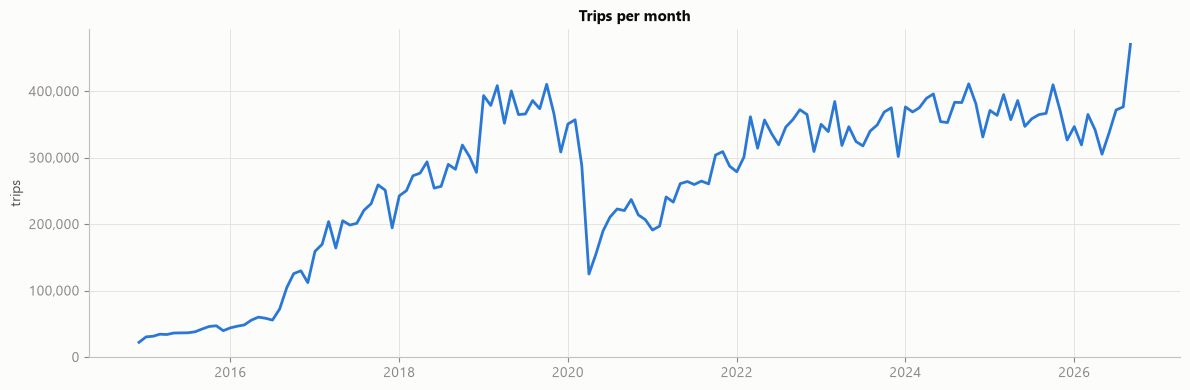

In [6]:
monthly = start.dt.to_period("M").value_counts().sort_index()
plots.plot_lines(monthly.to_timestamp().to_frame("trips"), "Trips per month", "trips");

In [7]:
yearly = start.dt.year.value_counts().sort_index().to_frame("trips")
yearly["growth_pct"] = yearly["trips"].pct_change() * 100
yearly["months"] = start.dt.to_period("M").groupby(start.dt.year).nunique()
yearly

,trips,growth_pct,months
Inicio_del_viaje,,,
2014,22016,NaN,1
2015,450636,1946.856831,12
2016,911350,102.236395,12
2017,2456030,169.493608,12
2018,3316575,35.038049,12
2019,4506607,35.881354,12
2020,2774920,-38.425516,12
2021,3070805,10.662830,12
2022,4015857,30.775383,12


**Result → action.** Demand grew from about 37k trips per month in 2015 to about 400k at the 2019 peak, collapsed in April 2020 (COVID-19 lockdown, −38% for the year) and did not recover until 2022. Since 2023 it has been on a plateau of 4.1-4.5M trips a year, with the yearly low in December or January. September 2026, the latest month, is the highest ever (470k vs 300-410k in the previous two years). Together with the station ids missing from the nomenclature (notebook 1.02, T8), it may signal a network expansion; it is worth monitoring as drift. 2026 has only 9 months. → Splits must be time-based, and 2020-2021 is a regime change that a demand model must either model explicitly or leave out of training.

## 3. Temporal demand patterns

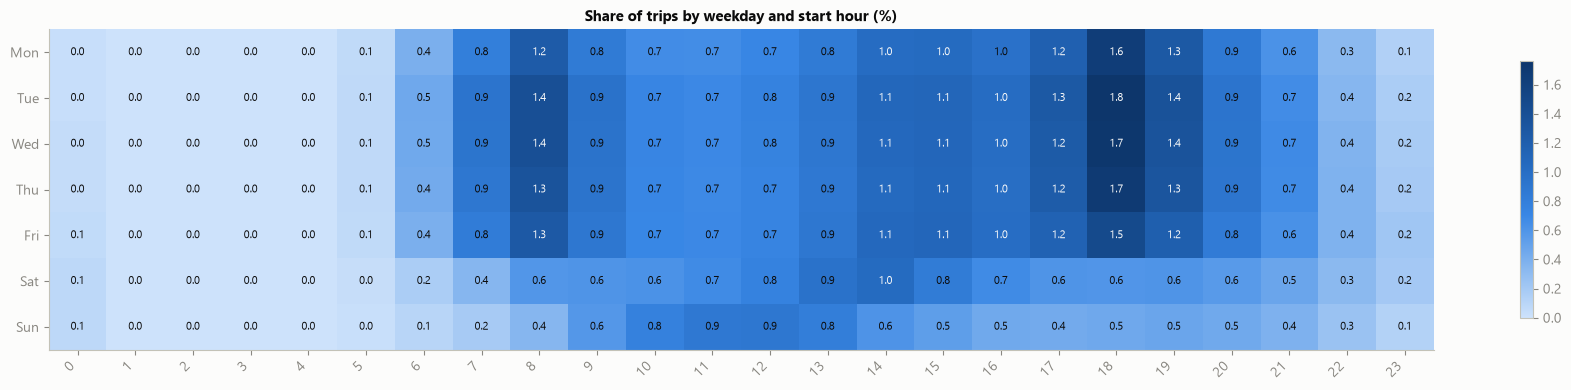

In [8]:
hour_weekday = pd.crosstab(features["weekday"], features["hour"], normalize="all") * 100
hour_weekday.index = WEEKDAYS
plots.plot_heatmap(hour_weekday, "Share of trips by weekday and start hour (%)", fmt="{:.1f}", figsize=(18, 4));

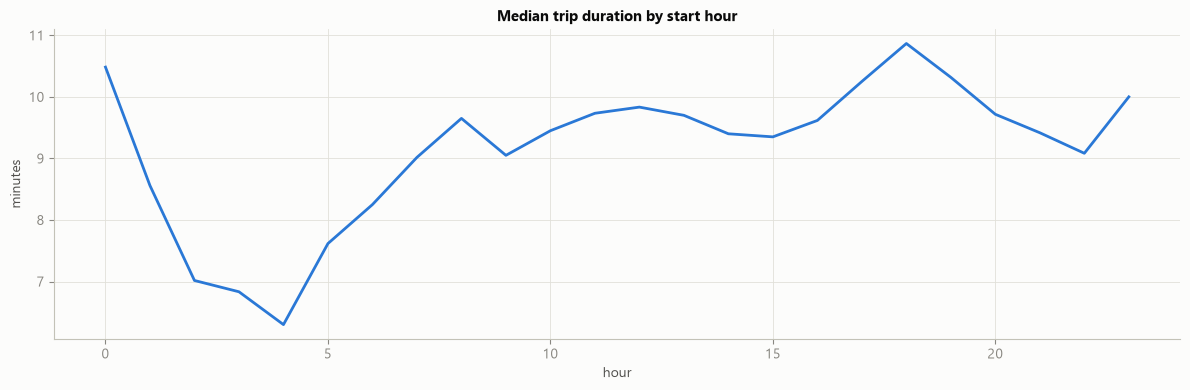

In [9]:
plots.plot_lines(
    features.groupby("hour")[["duration_min"]].median(),
    "Median trip duration by start hour", "minutes", xlabel="hour",
);

**Result → action.** Weekdays show the classic commuter profile: peaks at 8:00 and 18:00 (up to 1.8% of all trips in a single weekday hour), a midday plateau and almost no trips between 1:00 and 5:00, when the system is practically closed. Weekends have a single, flatter midday peak (Sunday 10:00-13:00). The median duration stays between 9 and 11 minutes from 8:00 to midnight, reaches its maximum at the 18:00 peak and is shortest at dawn. → Hour and weekday are the key temporal features for demand, and their interaction matters (the morning peak exists only on weekdays).

## 4. Categorical variable: `Genero`

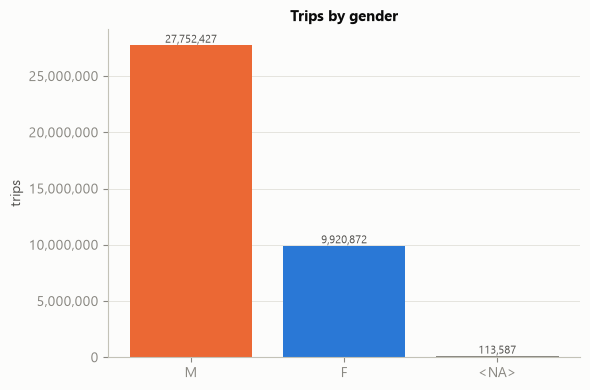

In [10]:
plots.plot_bars(gender.value_counts(), "Trips by gender", ylabel="trips");

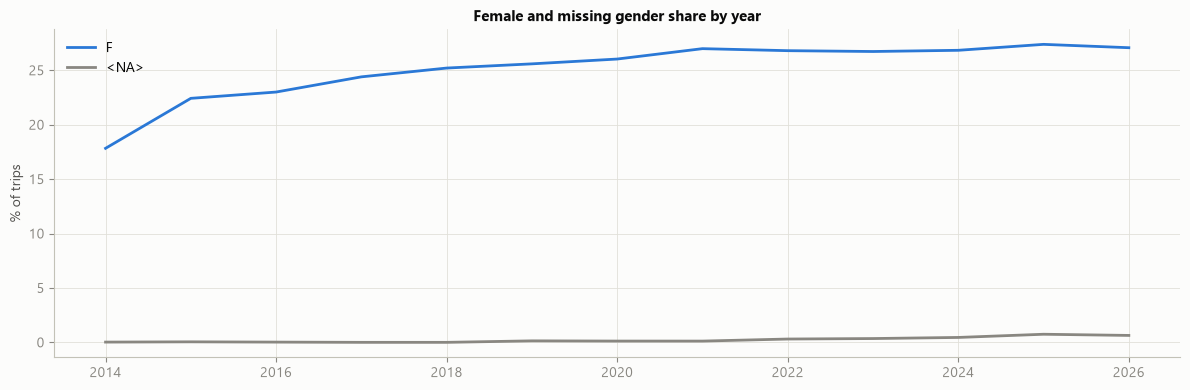

In [11]:
plots.plot_lines(
    eda.share_by_group(gender, start.dt.year, include_missing=False)[["F", "<NA>"]],
    "Female and missing gender share by year", "% of trips",
);

**Result → action.** 73% of the trips are by men. The female share grew from 18% (2014) to 27% (2021) and has been flat since. The missing-gender share stays below 1% every year. → Gender is a stable, low-cardinality attribute; the slow drift in its share is a reason to monitor input distributions over time.

## 5. Univariate analysis

The histogram shows the shape (clipped at p99.5 so the bulk is readable); the boxplot shows the spread. With millions of trips the outlier points are hidden; section 6 counts them.

In [12]:
eda.univariate_summary(features)

,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis
duration_min,37786886.0,11.422373,11.814486,1.0,6.050000,9.700000,14.916667,1439.199951,9.700000,41.116341,3176.750488
distance_km,37782979.0,1.511767,1.069093,0.0,0.742048,1.262314,2.047999,13.509099,1.262314,1.279684,2.194966
age,37712866.0,33.350067,10.562028,16.0,26.000000,30.000000,39.000000,90.000000,30.000000,1.136580,0.986049
speed_kmh,37782979.0,8.635018,3.645032,0.0,6.704893,8.847013,10.921902,29.999310,8.847013,-0.264567,0.483694
hour,37786886.0,14.194391,4.640487,0.0,10.000000,15.000000,18.000000,23.000000,15.000000,-0.183120,-0.895874
weekday,37786886.0,2.678487,1.868504,0.0,1.000000,3.000000,4.000000,6.000000,3.000000,0.179479,-1.060773


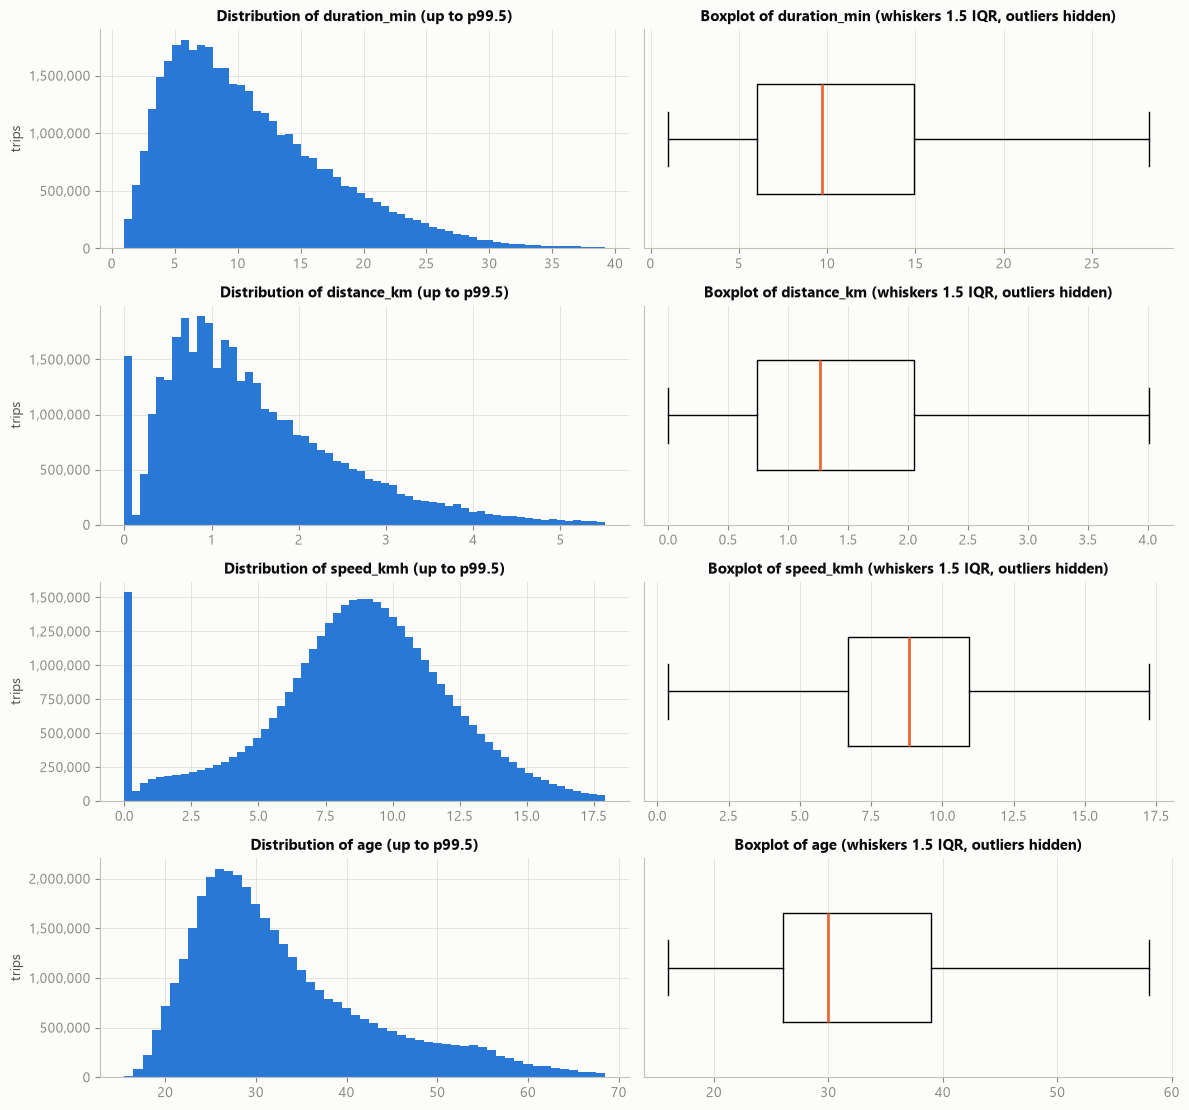

In [13]:
plots.plot_hist_box(features[['duration_min', 'distance_km', 'speed_kmh', 'age']]);

**Result → action.** After cleaning, the summary is physically plausible: the median trip lasts 9.7 min and covers 1.26 km at 8.8 km/h, and riders are 16-90 years old with a median of 30.
- Duration is strongly right-skewed (skewness 41; trips up to 24 h remain by design) → use log1p or robust scaling, or clip at a high quantile, if it becomes a feature or target.
- Distance has a spike at 0 (the 4% round trips). It is a straight line between stations, so a round trip carries no distance information → a round-trip flag is more informative than a 0 km distance.
- Speed is roughly symmetric around 9 km/h, apart from the same spike at 0.
- Age is right-skewed (median 30, long tail to 90).

## 6. Potential outliers (IQR rule)

Observations outside $[Q1 - 1.5\,IQR,\; Q3 + 1.5\,IQR]$ are *potential* outliers, not errors: the errors were removed by the cleaning contract. This is a diagnostic for later transformations (log, robust scaling, clipping).

In [14]:
eda.iqr_outliers(features.drop(columns=['hour', 'weekday']))

,lower_bound,upper_bound,n_potential_outliers,outlier_pct
speed_kmh,0.379380,17.247414,1847546,4.889384
distance_km,-1.216879,4.006926,1176891,3.114549
age,6.500000,58.500000,1117561,2.957537
duration_min,-7.250000,28.216667,852590,2.256312


**Result → action.** Between 2% and 5% of the values per feature are potential outliers. They are the natural tails of skewed variables (long leisure rides, older riders, round trips at 0 km/h); the impossible values were already removed by the contract → no further filtering. The IQR stays as a diagnostic that informs the choice of robust transformations.

## 7. Bivariate analysis

In [15]:
by_gender = features[["duration_min", "distance_km", "speed_kmh", "age"]].assign(Genero=gender)
by_gender.groupby("Genero", observed=True).agg(["mean", "median", "std"]).round(2).T

Genero                       F          M   <NA>
duration_min mean    11.670000  11.330000  13.35
             median   9.970000   9.600000  10.35
             std     12.010000  11.700000  19.67
distance_km  mean     1.480000   1.520000   1.57
             median   1.260000   1.260000   1.32
             std      0.990000   1.100000   1.08
speed_kmh    mean     8.190000   8.800000   8.35
             median   8.350000   9.060000   8.57
             std      3.260000   3.760000   3.58
age          mean    30.959999  34.220001  28.18
             median  28.000000  31.000000  27.00
             std      8.980000  10.950000   5.98

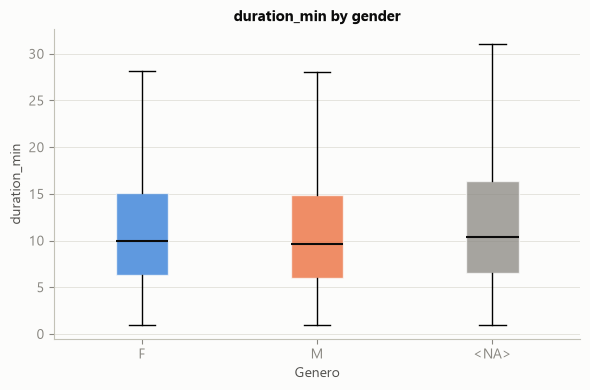

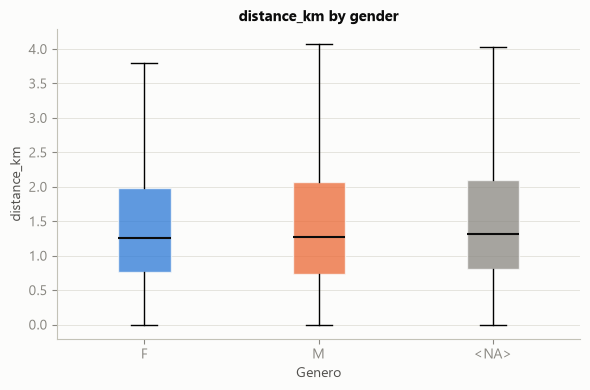

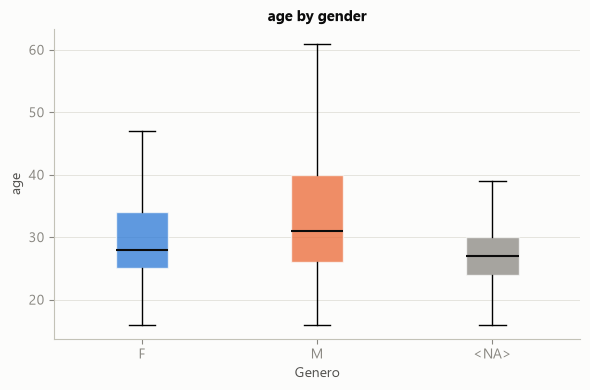

In [16]:
for column in ["duration_min", "distance_km", "age"]:
    plots.plot_box_by(by_gender, column, "Genero", f"{column} by gender")

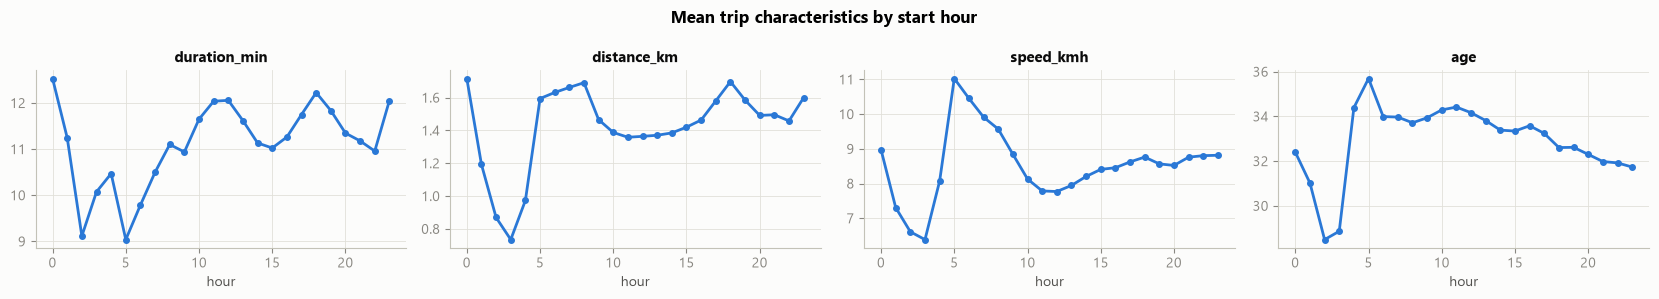

In [17]:
plots.plot_grouped_means(
    features.groupby("hour")[["duration_min", "distance_km", "speed_kmh", "age"]].mean(),
    "Mean trip characteristics by start hour",
    ncols=4,
);

**Result → action.** Women ride slightly slower than men (median 8.4 vs 9.1 km/h) over similar distances, and are younger on average (31 vs 34). Riders with unknown gender form a distinct group: younger (28) with much less age spread, and with longer, more variable trips (std 19.7 vs 12 min). By hour, early-morning trips (5:00-8:00) are the fastest and cover more distance, which is consistent with commuting. Mean rider age also peaks at 5:00. → Gender is a weak predictor of trip characteristics and the hour a stronger one. "Unknown" must stay its own category, not be filled.

## 8. Stations

In [18]:
origins = trips["Origen_Id"].value_counts()
destinations = trips["Destino_Id"].value_counts()
top_share = origins.head(int(len(origins) * 0.1)).sum() / origins.sum()
print(f"Active origin stations: {len(origins)}; the top 10% start {top_share:.1%} of the trips")
print(f"Round trips (same origin and destination): {(trips['Origen_Id'] == trips['Destino_Id']).mean():.2%}")
names = stations.set_index("id")["name"]
origins.head(10).to_frame("trips").join(names)

Active origin stations: 486; the top 10% start 39.5% of the trips
Round trips (same origin and destination): 4.02%


,trips,name
Origen_Id,,
51,810191,(GDL-049) Lopez Cotilla / Penitenciaría
11,582334,(GDL-009) Calz. Federalismo/ C. J. Angulo
50,568554,(GDL-048) C. Constancio Hernández/ Av. Juaréz
52,548729,(GDL-050) C.Pedro Moreno /Federalismo
35,547243,(GDL-033) Av. Hidalgo / C. Pedro Loza
54,489245,(GDL-052) Av. Juarez /16 de Septiembre
271,461519,(GDL-198) Av. Alcalde / C. Hospital
194,401508,(GDL-127) Av. Vallarta / Av. de Los Arcos
75,389615,(GDL-073) Av. La Paz / Av. Federalismo


In [19]:
net_flow = destinations.sub(origins, fill_value=0).sort_values().rename("arrivals_minus_departures")
pd.concat([net_flow.head(5), net_flow.tail(5)]).to_frame().join(names)

,arrivals_minus_departures,name
Destino_Id,,
194,-170295,(GDL-127) Av. Vallarta / Av. de Los Arcos
197,-56087,(GDL-130) C. J. Ruíz de Alarcón / Av Vallarta
196,-50313,(GDL-129) C. Lope de Vega / Av. Vallarta
195,-44042,(GDL-128) Av. Morelos / C. Emilio Castelar
11,-42812,(GDL-009) Calz. Federalismo/ C. J. Angulo
78,73332,(GDL-076) Calz. Revolución / C. San Fernando
35,75536,(GDL-033) Av. Hidalgo / C. Pedro Loza
56,81181,(GDL-054) Av. Juárez / Calz. Independencia
34,108620,(GDL-032) C. Degollado / Av. Miguel Hidalgo


**Result → action.** Demand is concentrated: the top 10% of the 486 stations start 39.5% of the trips, led by the downtown Guadalajara corridor (López Cotilla, Federalismo, Juárez, Hidalgo). Flows are strongly unbalanced. The Av. Vallarta / Los Arcos cluster (GDL-127 to GDL-130) has about 320k more departures than arrivals (170k at GDL-127 alone), while López Cotilla / Penitenciaría receives 241k more than it sends. → Station-level models need the station id (or its location) as a feature, and net flow is the quantity a rebalancing use case would predict.

## 9. Correlations

Pearson measures linear relationships; Spearman, monotonic ones based on ranks. A Spearman much stronger than Pearson points to a monotonic but non-linear relationship. Both use the trips with every feature known (unknown stations and missing ages excluded), so they are computed on the same rows.

Trips with every feature known: 37,708,959 (99.79%)


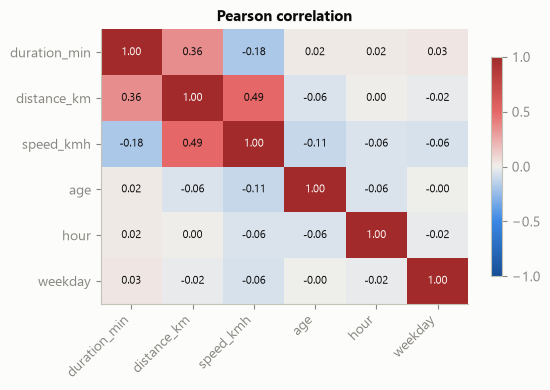

In [20]:
complete = features.dropna()
print(f"Trips with every feature known: {len(complete):,} ({len(complete) / len(features):.2%})")
pearson = complete.corr(method="pearson")
plots.plot_heatmap(pearson, "Pearson correlation", diverging=True, vmax=1);

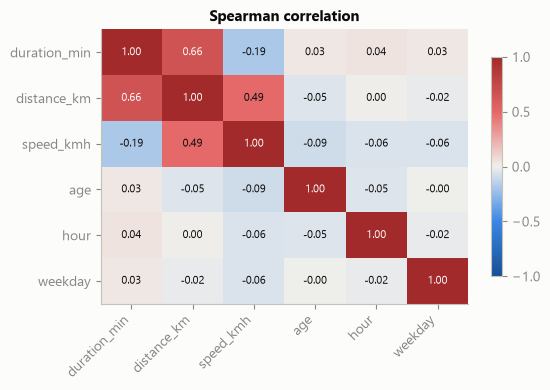

In [21]:
spearman = complete.corr(method="spearman")
plots.plot_heatmap(spearman, "Spearman correlation", diverging=True, vmax=1);

In [22]:
pairs = eda.top_correlated_pairs(pearson, n=6)
pairs["spearman"] = [spearman.loc[a, b] for a, b in zip(pairs["feature_1"], pairs["feature_2"])]
pairs.round(3)

,feature_1,feature_2,correlation,abs_correlation,spearman
0,distance_km,speed_kmh,0.493,0.493,0.486
1,duration_min,distance_km,0.355,0.355,0.663
2,duration_min,speed_kmh,-0.183,0.183,-0.187
3,speed_kmh,age,-0.112,0.112,-0.092
4,speed_kmh,weekday,-0.065,0.065,-0.062
5,age,hour,-0.059,0.059,-0.052


**Result → action.** Correlations are weak overall, so multicollinearity is not a concern. The strongest pairs are mechanical: distance-speed (0.49) and duration-distance (Pearson 0.36 vs Spearman 0.66, a monotonic but non-linear relation bent by long leisure rides that cover little straight-line distance). Speed decreases slightly with age (−0.11). Hour and weekday barely correlate *linearly* with trip characteristics, yet sections 3 and 7 show strong non-linear patterns → encode them cyclically or as categories, not as plain numbers.

## 10. Focused pairwise view (random sample)

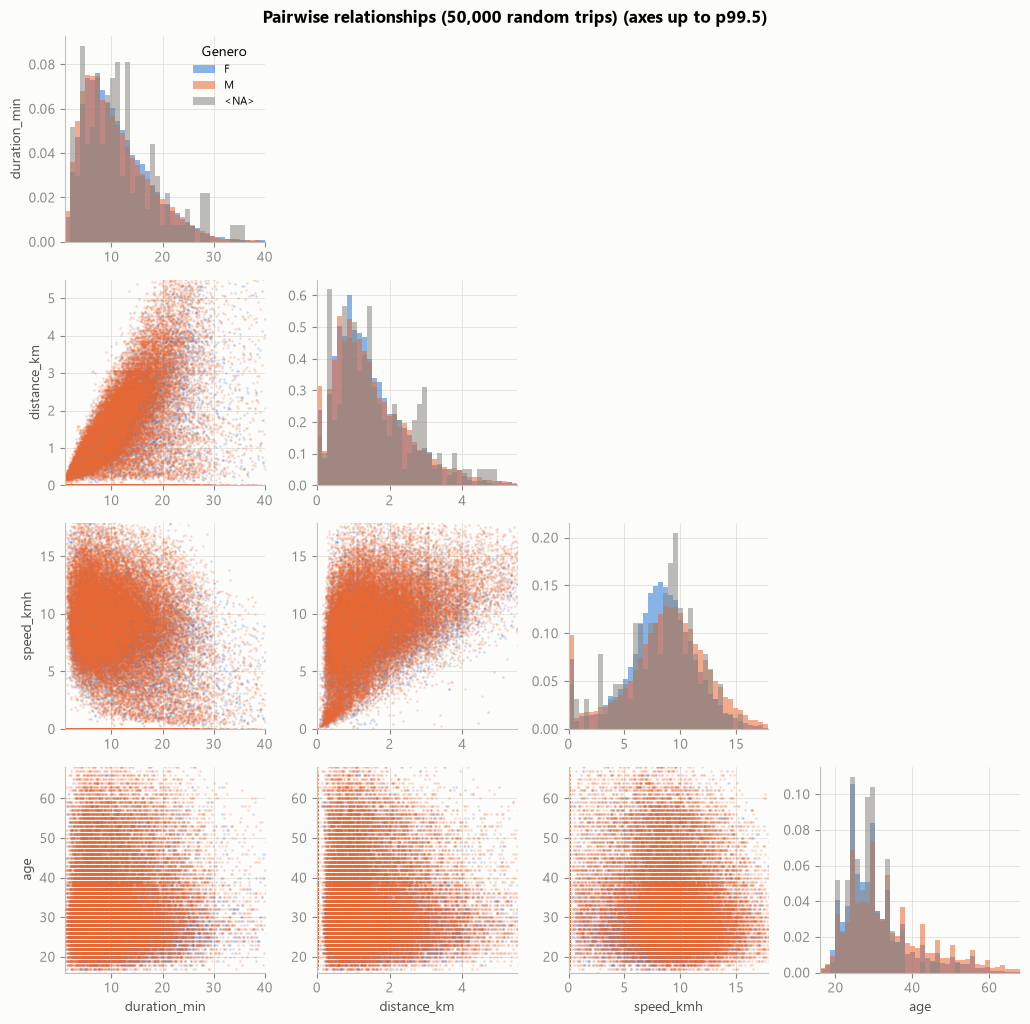

In [23]:
sample = features.sample(SAMPLE_SIZE, random_state=SEED)
plots.plot_scatter_matrix(
    sample[["duration_min", "distance_km", "speed_kmh", "age"]],
    gender.loc[sample.index],
    f"Pairwise relationships ({SAMPLE_SIZE:,} random trips)",
);

## 11. Standardized profile by gender

Each value is how far the group's mean is from the overall mean, in standard deviations. The `<NA>` row shows whether riders with unknown gender behave differently, which decides whether "unknown" is informative for a model.

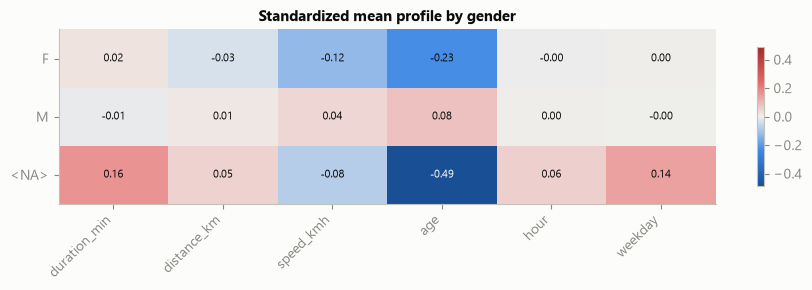

In [24]:
profile = eda.standardized_profiles(features, gender)
plots.plot_heatmap(profile, "Standardized mean profile by gender", diverging=True, figsize=(9, 3));

**Result → action.** M and F differ mainly in speed and age (F: −0.12 and −0.23 std). The `<NA>` group stands out more than either: 0.49 std younger, with longer trips (+0.16) and more weekend trips (+0.14). Missing gender is therefore informative. This is consistent with the cleaning decision in `1.02` to keep it as `<NA>` rather than fill it, and it means a model should see "unknown" as its own category.

> The purpose of EDA is not to justify a model that has already been selected. It is to identify properties of the data that should inform subsequent decisions.

## Findings and implications for the next stages

- *Splits:* growth until 2019, the 2020-2021 COVID regime change and the yearly seasonality require time-based splits; random splits would leak future demand.
- *Demand structure:* weekday commuter peaks at 8:00 and 18:00, a different weekend profile, strong concentration in downtown stations, and large net flows between station clusters. Volume by station and time is the most structured signal in the data.
- *Features:* the hour × weekday interaction, cyclical encodings, station id or location, a round-trip flag and log-scaled duration. Age and gender are weak predictors of trip characteristics, and "unknown gender" behaves as its own group.
- *Station metadata:* only the latest nomenclature exists, three station ids from 2026 are missing from it, and locations may change over time → coordinate-based features need a station history.
- *Monitoring:* monthly volume (September 2026 is a record), the female share, the missing-gender rate and new station ids all drift over time. `validate` should gate every new month, and these distributions should be tracked for drift.